<a href="https://colab.research.google.com/github/manasabt1997-max/Data-science/blob/main/single_cell_analysis_using_scanpy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scanpy
import scanpy as sc

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 74.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 96.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 27.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 19.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 6.6 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take i

In [3]:
!git clone https://github.com/scverse/scanpy-tutorials.git%cd scanpy-tutorials/pbmc3k

Cloning into 'scanpy-tutorials/pbmc3k'...
fatal: unable to access 'https://github.com/scverse/scanpy-tutorials.git%cd/': The requested URL returned error: 400


In [4]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
#load example dataset
adata = sc.datasets.pbmc68k_reduced()

In [7]:
#annotate mitochondrial genes
adata.var['mt'] = adata.var_names.str.startswith('MT-')

In [8]:
#calculate QC matrics
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt'],percent_top= None, log1p= False, inplace=True)
adata.obs.head()

,bulk_labels,n_genes,percent_mito,n_counts,S_score,G2M_score,phase,louvain,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt
index,,,,,,,,,,,,
AAAGCCTGGCTAAC-1,CD14+ Monocyte,1003,0.023856,2557.0,-0.119160,-0.816889,G1,1,765,3.989997,4.011,100.526390
AAATTCGATGCACA-1,Dendritic,1080,0.027458,2695.0,0.067026,-0.889498,S,1,765,6.876002,-0.490,-7.126235
AACACGTGGTCTTT-1,CD56+ NK,1228,0.016819,3389.0,-0.147977,-0.941749,G1,3,765,56.836998,-0.490,-0.862114
AAGTGCACGTGCTA-1,CD4+/CD25 T Reg,1007,0.011797,2204.0,0.065216,1.469291,G2M,9,765,23.085995,-0.490,-2.122499
ACACGAACGGAGTG-1,Dendritic,1178,0.017277,3878.0,-0.122974,-0.868185,G1,2,765,-37.153999,-0.490,1.318835


In [10]:
#filter low quality cells
sc.pp.filter_cells(adata, min_counts=200)
adata = adata[adata.obs['n_genes_by_counts']< 5000, :]
adata = adata[adata.obs['pct_counts_mt']<20, :]
#filter low quality/ rare genes
sc.pp.filter_genes(adata, min_cells=3)
print(f'Number of cells in adata: {adata.n_obs}')
print(f'Number of genes in adata: {adata.n_vars}')
print(f'retained {adata.n_obs} cells and {adata.n_vars} genes.')

Number of cells in adata: 0
Number of genes in adata: 0
retained 0 cells and 0 genes.


/usr/local/lib/python3.13/dist-packages/scanpy/preprocessing/_simple.py:280: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var["n_cells"] = number


In [11]:
#normalize and log transformation
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
print(f'Processed data shape:{adata.shape}')
print('Normalization and log transformation complete!')

Processed data shape:(0, 0)
Normalization and log transformation complete!


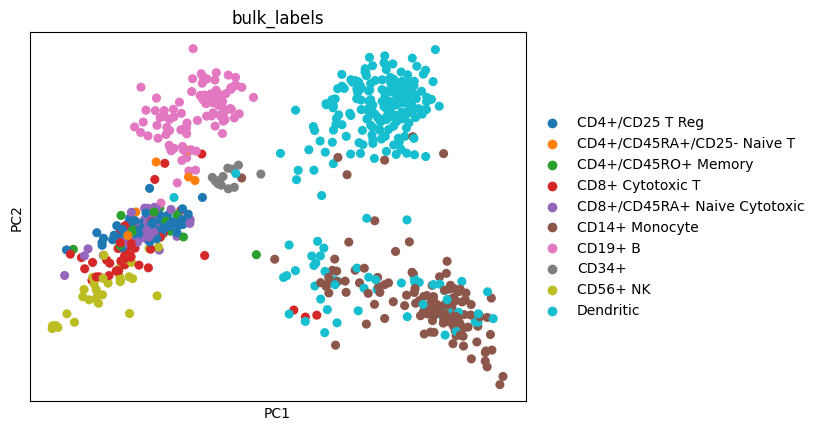

In [15]:
# Reload clean preprocessed dataset since previous filters emptied it
adata = sc.datasets.pbmc68k_reduced()

# Scale, run PCA, and plot labeled components
sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata)
sc.pl.pca(adata, color='bulk_labels')

In [17]:
# Install necessary dependencies for Leiden clustering
!pip install -q igraph leidenalg

# leiden clustering (corrected version)
sc.tl.leiden(adata, flavor='igraph', directed=False, n_iterations=2)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 54.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 56.0 MB/s eta 0:00:00


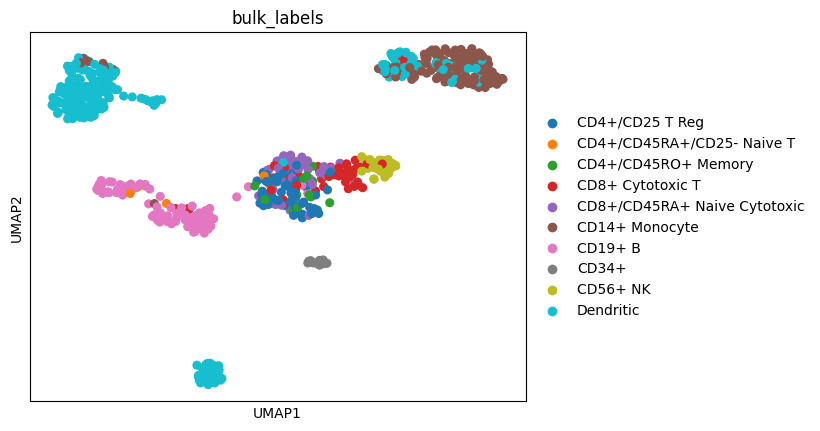

In [20]:
#UMAP visualization
sc.tl.umap(adata)
sc.pl.umap(adata, color='bulk_labels')

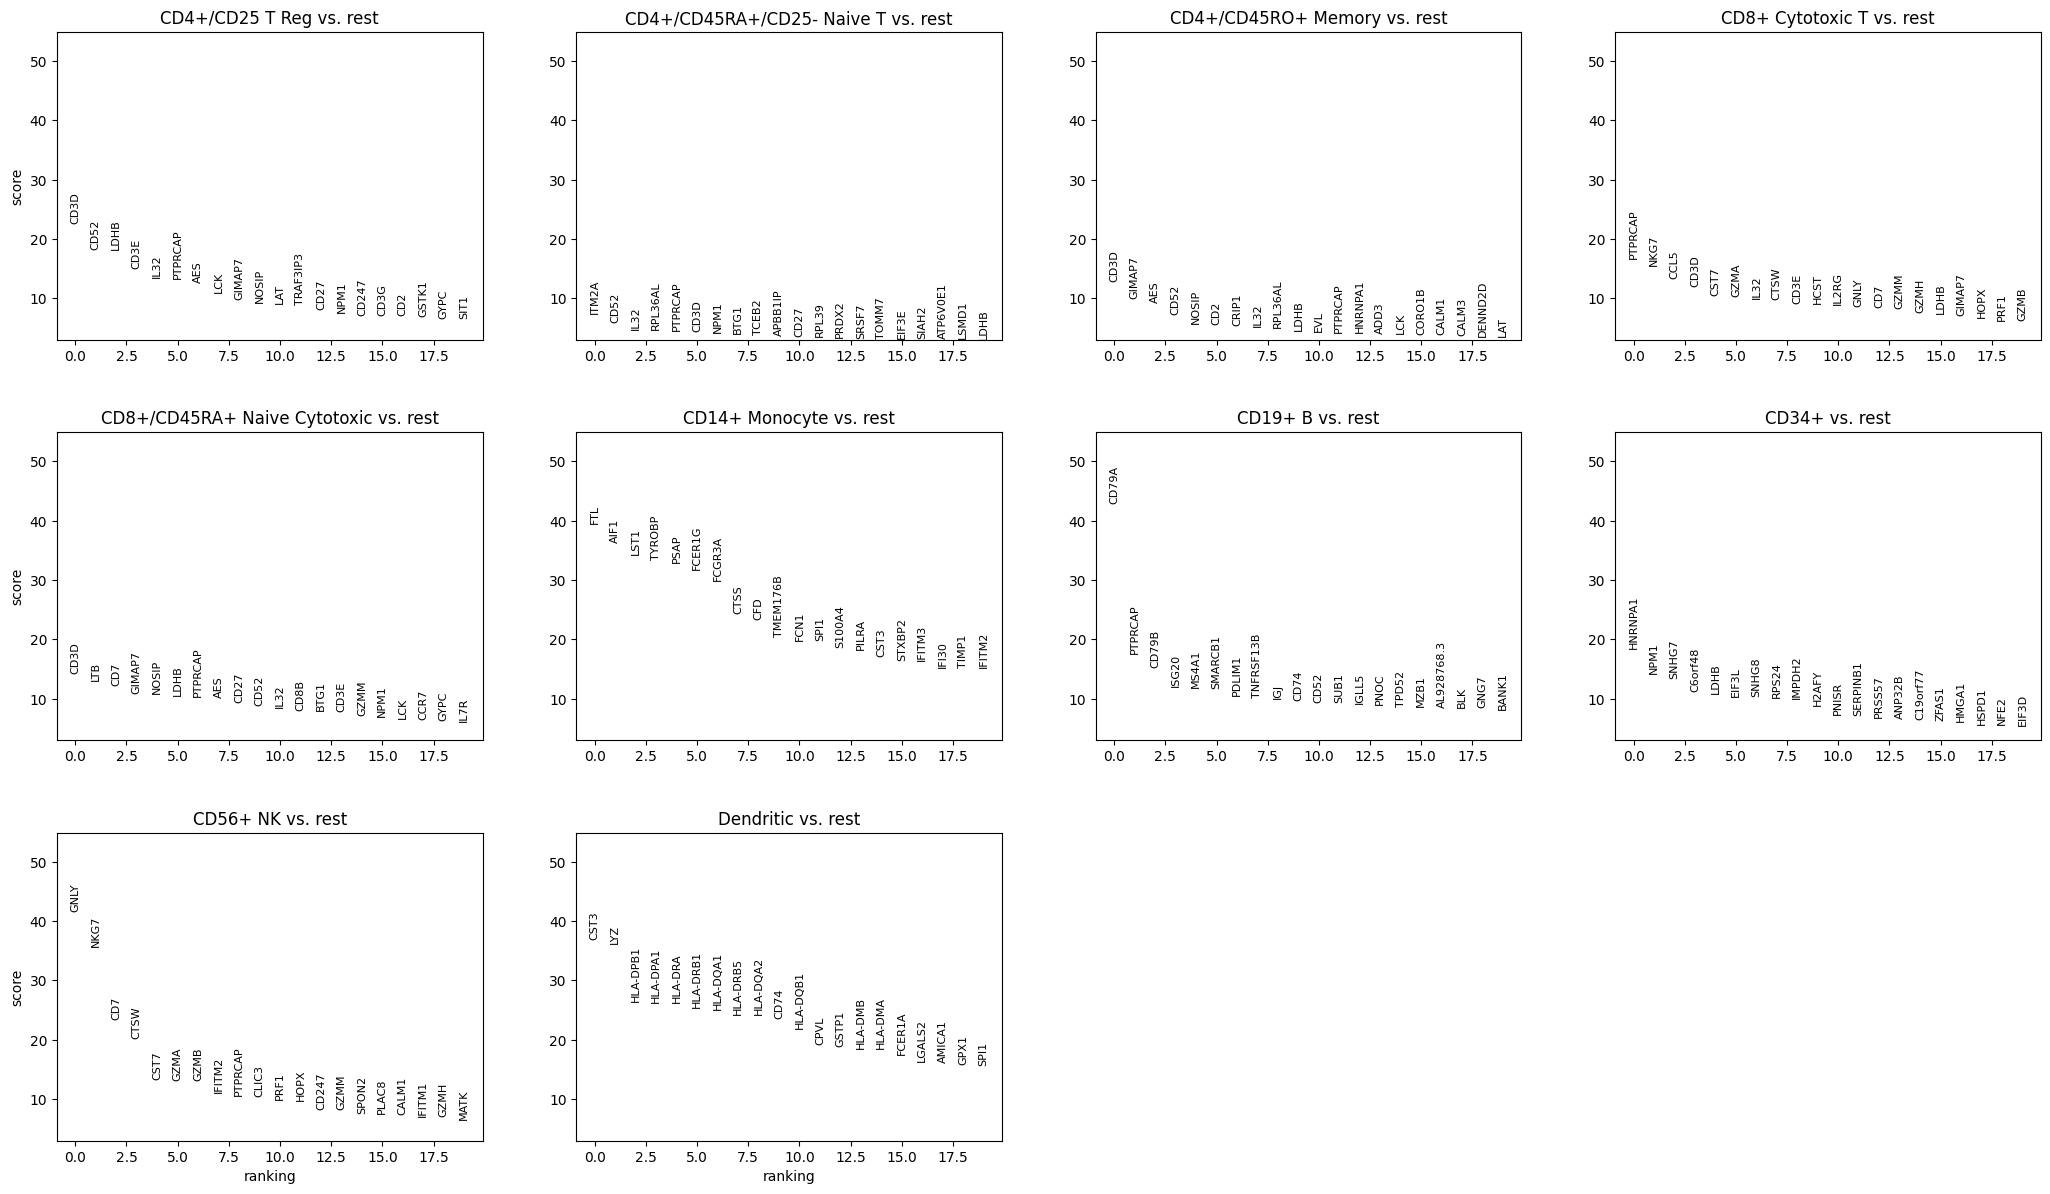

In [21]:
#diferential gene expression
sc.tl.rank_genes_groups(adata, groupby='bulk_labels', method='t-test')
sc.pl.rank_genes_groups(adata, n_genes=20)

In [23]:
#save processed data
adata.write('pbmc_processed.h5ad')

# Correctly import files from google.colab to enable downloading
from google.colab import files
files.download('pbmc_processed.h5ad')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>